In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import optimizers

print(tf.__version__)

2026-10-18 15:46:47.963022: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-18 15:46:47.993643: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F AVX512_VNNI AVX512_BF16, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2.19.1


In [20]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

In [21]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [16]:
train_images.shape

(60000, 28, 28)

In [5]:
len(train_labels)

60000

In [6]:
train_labels

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

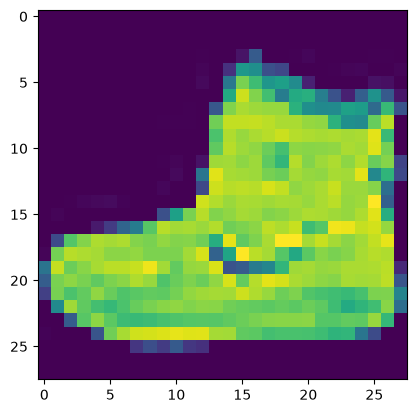

In [7]:
plt.figure()
plt.imshow(train_images[0])
plt.grid(False)
plt.show()

In [22]:
train_images = train_images / 255.0
test_images = test_images / 255.0

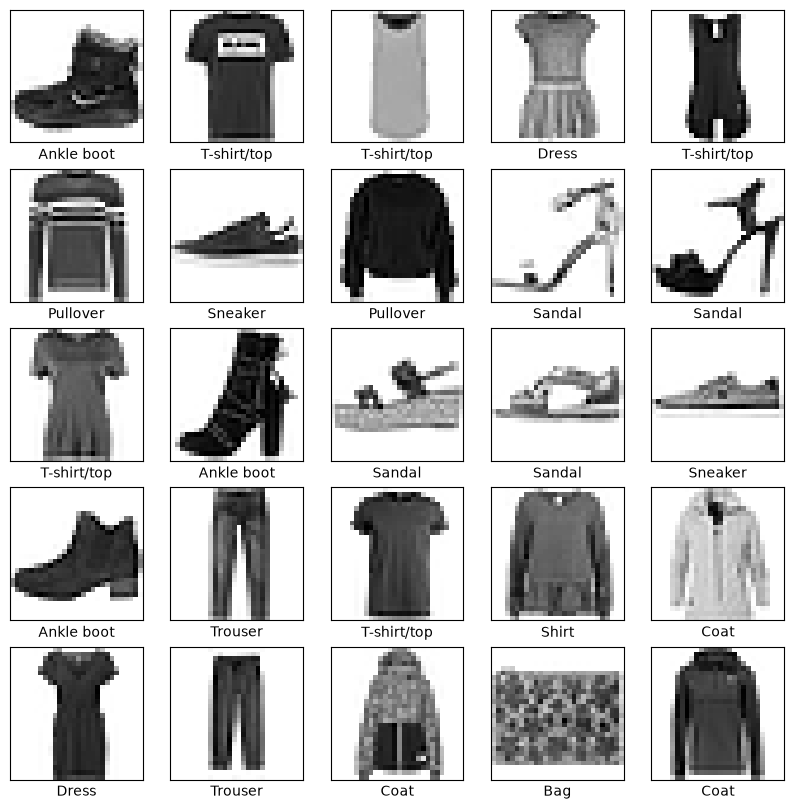

In [9]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

In [10]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

/home/noob/anaconda3/envs/ai_env/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [12]:
model.fit(
    train_images, 
    train_labels, 
    epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 853us/step - accuracy: 0.8222 - loss: 0.5042
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8627 - loss: 0.3806
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8760 - loss: 0.3395
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8831 - loss: 0.3166
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8897 - loss: 0.2992
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8956 - loss: 0.2824
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8996 - loss: 0.2700
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9028 - loss: 0.2618
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9073 - loss: 0.2511
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9094 - loss: 0.2444


In [23]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('\nTest accuracy:', test_acc)

313/313 - 0s - 931us/step - accuracy: 0.8832 - loss: 0.3308

Test accuracy: 0.8831999897956848


In [29]:
probability_model = tf.keras.Sequential([model, 
                                         tf.keras.layers.Softmax()])

In [30]:
predictions = probability_model.predict(test_images)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 613us/step


In [31]:
predictions[0]

array([8.2824123e-11, 6.7040701e-10, 2.6736452e-11, 1.3748288e-15,
       2.7533079e-10, 8.6483400e-05, 6.8544636e-12, 4.4614207e-03,
       1.0499152e-09, 9.9545211e-01], dtype=float32)

In [32]:
np.argmax(predictions[0])

np.int64(9)

In [33]:
test_labels[0]

np.uint8(9)

In [85]:
def plot_image(i, predictions_aray, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_aray)
    if predicted_label == true_label:
        color = 'green'
    else:
        color = 'red'

    plt.xlabel('{} {:2.0f}% ({})'.format(class_names[predicted_label],
                                         100*np.max(predictions_aray),
                                         class_names[true_label]),
                                         color=color)

def plot_value_array(i, predictions_aray, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])
    thisplot = plt.bar(range(10), predictions_aray, color='#777777')
    plt.ylim([0,1])
    predicted_label = np.argmax(predictions_aray)

    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('green')

def plot_ith_image(index, predictions_aray, test_labels, test_images, num_rows=1, num_cols=1):
    plt.figure(figsize=(2*2*num_cols,2*num_rows))
    for i in range(num_rows*num_cols):
        plt.subplot(num_rows, 2*num_cols, 2*i+1)
        plot_image(i+index, predictions_aray[i+index], test_labels, test_images)
        plt.subplot(num_rows,2*num_cols, 2*i+2)
        plot_value_array(i+index, predictions_aray[i+index], test_labels)
    plt.tight_layout()
    plt.show()

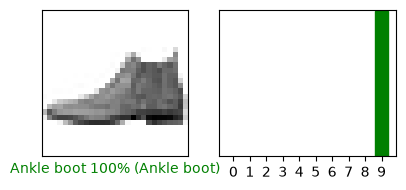

array([8.2824123e-11, 6.7040701e-10, 2.6736452e-11, 1.3748288e-15,
       2.7533079e-10, 8.6483400e-05, 6.8544636e-12, 4.4614207e-03,
       1.0499152e-09, 9.9545211e-01], dtype=float32)

In [86]:
i = 0
plot_ith_image(i, predictions, test_labels, test_images)
predictions[0]

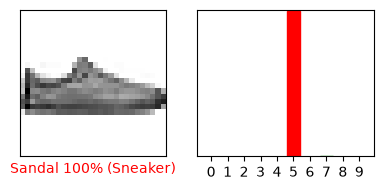

array([2.2364765e-14, 8.7339795e-15, 1.1798478e-13, 4.0177228e-10,
       4.6252282e-13, 9.9626094e-01, 4.0019845e-09, 2.3858167e-05,
       3.7151189e-03, 5.9061740e-13], dtype=float32)

In [87]:
i = 12
plot_ith_image(i, predictions, test_labels, test_images)
predictions[12]

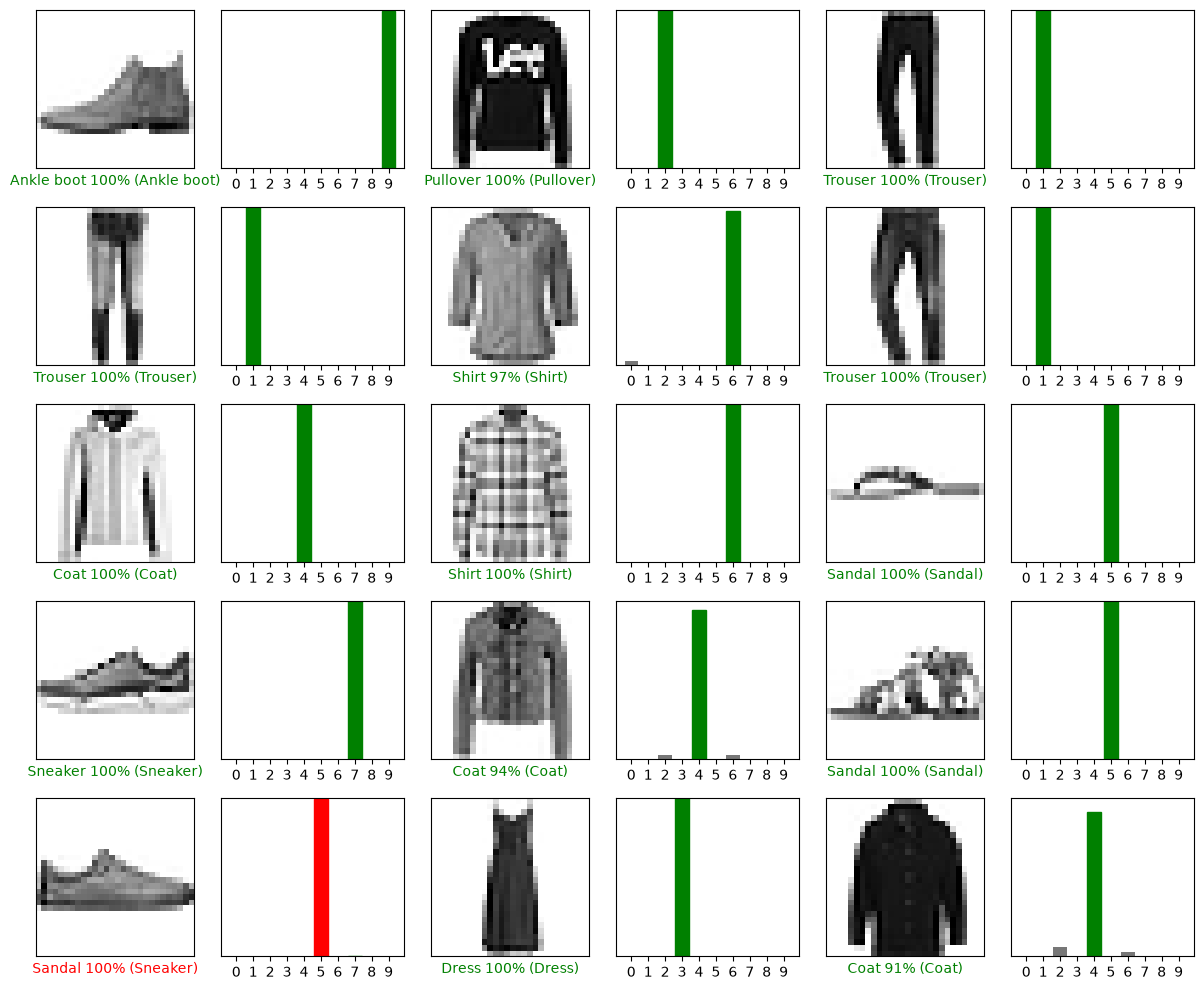

In [88]:
plot_ith_image(0, predictions, test_labels, test_images, num_rows=5, num_cols=3)

In [89]:
img = test_images[1]
print(img.shape)

(28, 28)


In [90]:
img = (np.expand_dims(img, 0))
print(img.shape)

(1, 28, 28)


In [91]:
predictions_single = probability_model.predict(img)
print(predictions_single)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
[[2.5947313e-04 5.2208560e-14 9.9882239e-01 2.1619869e-06 6.2663673e-04
  6.0711226e-15 2.8938643e-04 4.8203218e-18 2.1810245e-12 1.8012847e-14]]


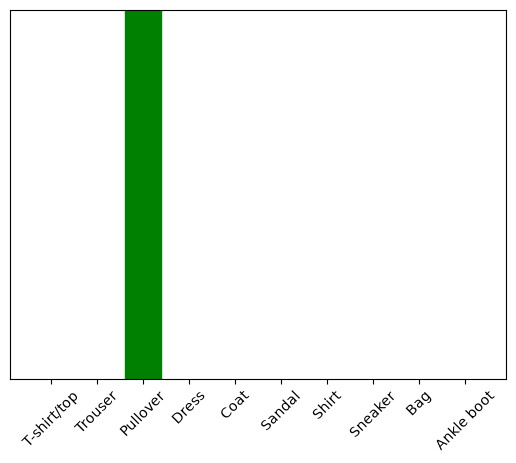

In [94]:
plot_value_array(1, predictions_single[0], test_labels)
# _ = discarts the value returned
_ = plt.xticks(range(10), class_names, rotation=45)
plt.show()

In [95]:
np.argmax(predictions_single[0])

np.int64(2)